# Create Training Features for Deep Ocean (DO) Regions

This notebook processes sediment rate labels and extracts environmental features from the Restrepo dataset for Deep Ocean (DO) regions. The features are extracted at the locations of sediment rate measurements and saved for subsequent model training.

In [1]:
# Import required libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import xarray as xr
from os import walk
from pathlib import Path
from shapely.geometry import Point
import geopandas as gpd
from geopandas import GeoDataFrame
import sys
import warnings

# Suppress warnings for cleaner output
warnings.filterwarnings('ignore')

# Get project root and add to path
project_root = Path().resolve().parents[0] if Path().resolve().name == 'notebooks' else Path().resolve()
if project_root.name != 'mtl-mar':
    project_root = project_root.parent
sys.path.insert(0, str(project_root / "src"))
from utils import DATA_RAW, DATA_INTERIM

In [2]:
def find_nearest(value, vector):
    """
    Find the index of the nearest value in a vector.
    
    Args:
        value: Target value to find
        vector: Array of values to search in
        
    Returns:
        Index of the nearest value in the vector
    """
    vector = np.float64(vector) - np.float64(value)
    return np.argmin(np.abs(vector))

## Load and Preprocess Sediment Rate Labels

In [3]:
# Load deep ocean sediment rate labels
data_path = DATA_RAW / "labels"
sed_labels_file = "sedrate_deep.csv"
df = pd.read_csv(data_path / sed_labels_file)


In [4]:
# Display basic information about the dataset
print(f"Total data points: {len(df)}")
print(f"Columns: {df.columns.tolist()}")
df.head()

Total data points: 7909
Columns: ['Unnamed: 0', 'Latitude', 'Longitude', 'Sedimentation rate [cm/ka]', 'MAR(g/cm**2/ka)']


,Unnamed: 0,Latitude,Longitude,Sedimentation rate [cm/ka],MAR(g/cm**2/ka)
0,0,-68.133,-126.750,0.58,0.36192
1,1,-68.117,-130.733,0.77,0.50050
2,2,-68.067,-106.800,0.74,0.46176
3,3,-68.050,-159.817,1.15,0.74750
4,4,-68.050,174.600,0.97,0.68094


Final data points after filtering: 7713


,Latitude,Longitude,MAR(g/cm**2/ka)
count,7713.000000,7713.000000,7713.000000
mean,12.210538,46.923092,67.982287
std,35.646465,90.719889,99.553314
min,-76.400000,-179.483000,0.000000
25%,5.970000,-25.625000,0.865280
50%,19.071398,113.162072,18.850000
75%,23.600000,118.245406,119.600000
max,89.000000,179.483000,3369.600000


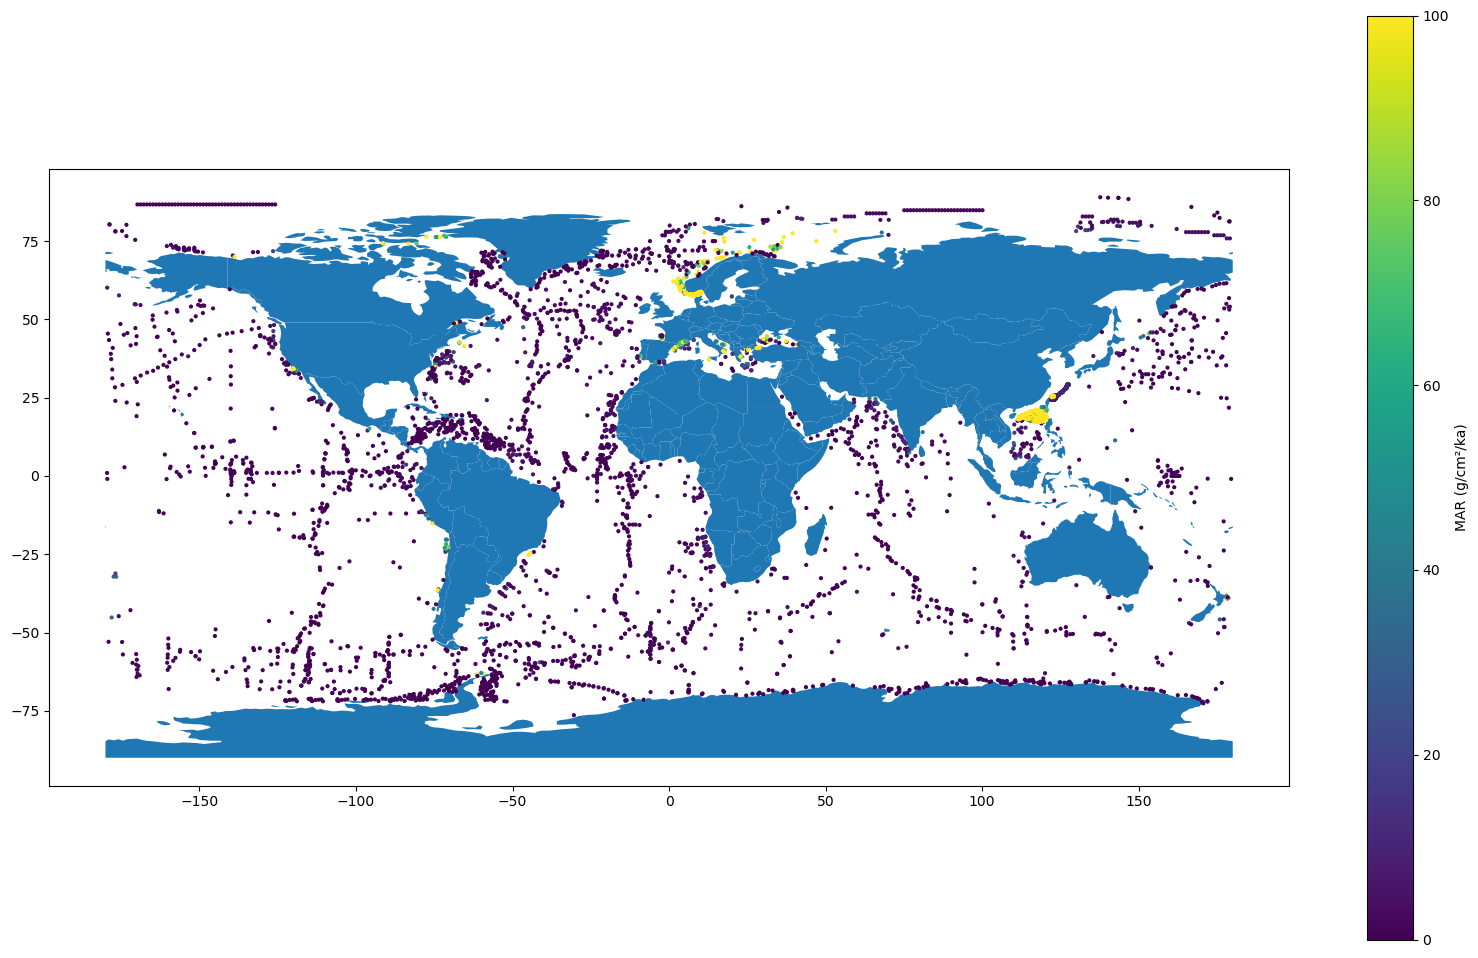

In [5]:
# Select relevant columns and filter data
df = df[["Latitude", "Longitude", "MAR(g/cm**2/ka)"]]
df = df[df["Longitude"] > -180]  # Remove invalid longitude values
df = df.dropna(how="any")  # Remove any rows with missing values

# Visualize data distribution
world = gpd.read_file(gpd.datasets.get_path('naturalearth_lowres'))
geometry = [Point(xy) for xy in zip(df['Longitude'], df['Latitude'])]
gdf = GeoDataFrame(df, geometry=geometry)
gdf.plot(ax=world.plot(figsize=(20, 12)), 
         column=df["MAR(g/cm**2/ka)"], 
         vmin=0, vmax=100,
         legend=True, 
         legend_kwds={"label": "MAR (g/cm²/ka)"}, 
         markersize=4)

# Display summary statistics
print(f"Final data points after filtering: {len(df)}")
df.describe()

## Load Feature Files and Apply Feature Selection

In [6]:
# Get list of all feature files
restrepo_features_path = DATA_RAW / "features" / "FeaturesPhrampusLee_TOCSedRate_updated"
restrepo_files = []

for (dirpath, dirnames, filenames) in walk(restrepo_features_path):
    restrepo_files.extend(filenames)

restrepo_files.sort()
print(f"Total feature files found: {len(restrepo_files)}")

Total feature files found: 510


In [7]:
# Load selected feature list
# header=None: first line is a feature filename, not a CSV column name
feature_selection = pd.read_csv(DATA_INTERIM / "selectedFeatureLists" / "selectedfeatures_v_men.txt", header=None).values.flatten()
print(f"Selected features: {len(feature_selection)}")

Selected features: 111


In [8]:
# Filter feature files to only include selected features
selected_files = [file for file in restrepo_files if file in feature_selection]
print(f"Files after feature selection: {len(selected_files)}")
restrepo_files = selected_files

Files after feature selection: 111


## Extract Features at Label Locations

In [9]:
# Save latitude and longitude arrays for later use
latitudes = np.array(df["Latitude"])
longitudes = np.array(df["Longitude"])
save_path = DATA_INTERIM / "inputfeatures" / "SedTOCFeaturesnoNAN_MAR_DO_men"
save_path.mkdir(parents=True, exist_ok=True)
np.save(save_path / "numpy_lat", latitudes)
np.save(save_path / "numpy_lon", longitudes)
print(f"Saved latitude and longitude arrays to {save_path}")



Saved latitude and longitude arrays to /gxfs_work/cau/sunms498/work/mtl-mar/data/interim/inputfeatures/SedTOCFeaturesnoNAN_MAR_DO_men


In [10]:
# Initialize feature arrays
# Features will be extracted at each label location for each feature file
restrepo_features = np.empty([len(df), len(restrepo_files)])
restrepo_features[:] = np.nan

# Arrays to store mean and std for normalization
restrepo_X_mean = np.empty(0)
restrepo_X_std = np.empty(0)

# Create latitude and longitude grids for feature extraction
# Grid spacing: 5 arc minutes = 5/60 = 0.0833333 degrees
latitudes_grid = np.linspace(-90, 90, 2160)  # 2160 points from -90 to 90
longitudes_grid = np.linspace(-180, 180, 4320)  # 4320 points from -180 to 180

# Find nearest grid indices for each label location
lat_idx = []
lon_idx = []
for data_idx in range(len(df)):
    lat_idx.append(find_nearest(df.iloc[data_idx, 0], latitudes_grid))
    lon_idx.append(find_nearest(df.iloc[data_idx, 1], longitudes_grid))

print(f"Initialized feature array: {restrepo_features.shape}")
print(f"Processing {len(restrepo_files)} feature files...")

Initialized feature array: (7713, 111)
Processing 111 feature files...


In [11]:
# Extract features from each file
file_idx = -1
corrupted_files = 0

for file in restrepo_files:
    file_idx += 1
    
    # Try to open the feature file
    try:
        rootgrp = xr.open_dataset(restrepo_features_path / file, format='NETCDF4')
    except Exception as e:
        # If file is corrupted, skip it
        restrepo_X_mean = np.append(restrepo_X_mean, np.nan)
        restrepo_X_std = np.append(restrepo_X_std, np.nan)
        corrupted_files += 1
        print(f"Warning: Could not load {file}: {e}")
        continue

    # Extract the data variable (most feature files use 'data' variable)
    dataset = rootgrp.variables['data']
    
    # Calculate mean and std for normalization
    restrepo_X_mean = np.append(restrepo_X_mean, np.nanmean(dataset))
    restrepo_X_std = np.append(restrepo_X_std, np.nanstd(dataset))
    
    # Special handling for elevation: remove points with elevation > 5m
    # (These are likely mislocated points, especially in Middle East region)
    if file == "GL_ELEVATION_M_ASL_ETOPO2v2.5m.grd":
        for data_idx in range(len(df)):
            elevation = dataset[lat_idx[data_idx], lon_idx[data_idx]]
            if elevation > 5:
                # Set to NaN to exclude from training
                restrepo_features[data_idx, file_idx] = np.nan
            else:
                restrepo_features[data_idx, file_idx] = elevation
    else:
        # Extract feature values at label locations
        for data_idx in range(len(df)):
            restrepo_features[data_idx, file_idx] = dataset[lat_idx[data_idx], lon_idx[data_idx]]
    
    # Track progress
    if (file_idx + 1) % 10 == 0:
        print(f"Processed {file_idx + 1}/{len(restrepo_files)} files...")

print(f"\nFeature extraction complete!")
print(f"Corrupted files: {corrupted_files}")

Processed 10/111 files...


Processed 20/111 files...


Processed 30/111 files...


Processed 40/111 files...


Processed 50/111 files...


Processed 60/111 files...


... (2 outputs left out)

Processed 90/111 files...


Processed 100/111 files...


Processed 110/111 files...



Feature extraction complete!
Corrupted files: 0


In [12]:
# Save extracted features and normalization parameters
features = np.concatenate([restrepo_features], axis=1)
X_mean = np.concatenate([restrepo_X_mean])
X_std = np.concatenate([restrepo_X_std])

print(f"Feature array shape: {features.shape}")
print(f"Mean array shape: {X_mean.shape}")
print(f"Std array shape: {X_std.shape}")

# Save to disk
save_path.mkdir(parents=True, exist_ok=True)
np.save(save_path / "numpy_features", restrepo_features)
np.save(save_path / "numpy_labels", df["MAR(g/cm**2/ka)"].values)
np.save(save_path / "features_mean", restrepo_X_mean)
np.save(save_path / "features_std", restrepo_X_std)
with open(save_path / "feature_files.txt", "w", encoding="utf-8") as f:
    f.write("\n".join(restrepo_files))

print(f"\nAll features saved to: {save_path}")
print(f"Feature count: {len(restrepo_files)} (see selectedFeatureLists/extrapolated_features_metadata.csv for shelf/ML extrapolation flags)")

Feature array shape: (7713, 111)
Mean array shape: (111,)
Std array shape: (111,)

All features saved to: /gxfs_work/cau/sunms498/work/mtl-mar/data/interim/inputfeatures/SedTOCFeaturesnoNAN_MAR_DO_men
Feature count: 111 (see selectedFeatureLists/extrapolated_features_metadata.csv for shelf/ML extrapolation flags)


In [13]:
# Verify saved files
print("Saved files:")
print(f"  - numpy_features.npy: {restrepo_features.shape}")
print(f"  - numpy_labels.npy: {df['MAR(g/cm**2/ka)'].values.shape}")
print(f"  - features_mean.npy: {restrepo_X_mean.shape}")
print(f"  - features_std.npy: {restrepo_X_std.shape}")
print(f"  - numpy_lat.npy: {latitudes.shape}")
print(f"  - numpy_lon.npy: {longitudes.shape}")

Saved files:
  - numpy_features.npy: (7713, 111)
  - numpy_labels.npy: (7713,)
  - features_mean.npy: (111,)
  - features_std.npy: (111,)
  - numpy_lat.npy: (7713,)
  - numpy_lon.npy: (7713,)
